# Module 03 — Eigenvalues, SVD and PCA

This notebook walks through the ideas of the module with code you can edit and re-run:
eigenvectors as the directions a matrix only stretches, power iteration and PageRank, the
spectral theorem, the singular value decomposition, low-rank approximation and image
compression, PCA from scratch on the Iris data, the pseudo-inverse, and the condition number.

Read the [concept guide](README.md) first, or keep it open alongside — every section here
mirrors a numbered section there. Code cells build each object **from scratch in NumPy**
first and then check against the library call that does the same.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Eigenvectors and eigenvalues — the directions a matrix only stretches

A square matrix $A$ moves every vector. A vector $v \ne 0$ with

$$A v = \lambda v$$

is only *scaled* (by the eigenvalue $\lambda$), never turned. For a $2\times2$ matrix the
eigenvalues solve the characteristic polynomial $\lambda^2 - \operatorname{tr}(A)\lambda + \det(A) = 0$.

Below we take $A = \begin{pmatrix} 4 & 1 \\ 2 & 3 \end{pmatrix}$, solve the polynomial by hand,
compare with `np.linalg.eig`, and draw what $A$ does to a grid. Watch the two coloured arrows:
they are the eigenvectors, and they come out pointing the same way they went in.

characteristic polynomial:  lambda^2 - 7 lambda + 10 = 0
eigenvalues by hand:        [5. 2.]
np.linalg.eig eigenvalues:  [5. 2.]
eigenvectors (unit length, as columns):
[[ 0.7071 -0.4472]
 [ 0.7071  0.8944]]
  A v1 = [3.5355 3.5355]   lambda1 v1 = [3.5355 3.5355]
  A v2 = [-0.8944  1.7889]   lambda2 v2 = [-0.8944  1.7889]
angle between eigenvectors: 71.6 degrees  (not orthogonal: A is not symmetric)


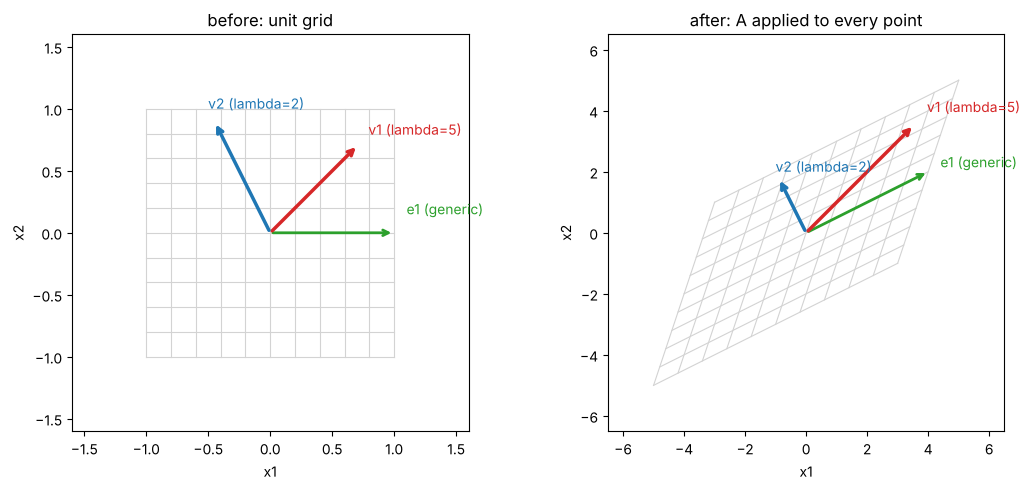

In [2]:
A = np.array([[4., 1.],
              [2., 3.]])

# --- eigenvalues by hand: lambda^2 - tr*lambda + det = 0
tr, det = np.trace(A), np.linalg.det(A)
disc = np.sqrt(tr**2 - 4 * det)
lam_hand = np.array([(tr + disc) / 2, (tr - disc) / 2])
print(f"characteristic polynomial:  lambda^2 - {tr:.0f} lambda + {det:.0f} = 0")
print("eigenvalues by hand:       ", lam_hand)

# --- NumPy
w, V = np.linalg.eig(A)
order = np.argsort(-w.real)              # sort descending so the two agree
w, V = w[order].real, V[:, order].real
print("np.linalg.eig eigenvalues: ", w)
print("eigenvectors (unit length, as columns):")
print(V)
for i in range(2):
    print(f"  A v{i+1} = {A @ V[:, i]}   lambda{i+1} v{i+1} = {w[i] * V[:, i]}")
print("angle between eigenvectors: %.1f degrees  (not orthogonal: A is not symmetric)"
      % np.degrees(np.arccos(abs(V[:, 0] @ V[:, 1]))))

# --- the grid picture
ts = np.linspace(-1, 1, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, M, title, lim in [(axes[0], np.eye(2), "before: unit grid", 1.6),
                          (axes[1], A, "after: A applied to every point", 6.5)]:
    for t in ts:
        for seg in (np.array([[t, t], [-1, 1]]), np.array([[-1, 1], [t, t]])):
            p = M @ seg
            ax.plot(p[0], p[1], color="lightgray", lw=0.8)
    g = M @ np.array([1., 0.])          # a generic vector: it gets turned
    ax.annotate("", xy=g, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:green", lw=2))
    ax.text(g[0] * 1.1, g[1] + 0.15, "e1 (generic)", color="tab:green")
    for i, c in enumerate(["tab:red", "tab:blue"]):
        u = M @ V[:, i]
        ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
        ax.text(u[0] * 1.12, u[1] * 1.12, f"v{i+1} (lambda={w[i]:.0f})", color=c)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.show()

Notice that the green vector $e_1$ is rotated as well as stretched, while the red and blue
eigenvectors keep their direction: $v_1 = (1, 1)/\sqrt2$ is stretched by $5$, and
$v_2 = (1, -2)/\sqrt5$ by $2$. The grid squares become parallelograms whose area is
multiplied by $\det A = 10 = \lambda_1 \lambda_2$. The two eigenvector *lines* meet at about
72 degrees, not 90 — orthogonality is a privilege reserved for symmetric matrices (Section 3).

**Try it yourself:** replace `A` with the rotation matrix `np.array([[0., -1.], [1., 0.]])`
(remove the `.real` calls first). The eigenvalues come out as $\pm i$ — no real direction
survives a rotation, so complex eigenvalues always signal a rotational component.

## 2. Diagonalisation, matrix powers and power iteration

With eigenvectors as columns of $P$ and eigenvalues in a diagonal $D$,
$A = PDP^{-1}$ and $A^k = PD^kP^{-1}$. Writing $x = \sum_i c_i v_i$,

$$A^k x = \sum_i c_i \lambda_i^k v_i ,$$

so the dominant eigenvalue takes over: $A^k x$ lines up with $v_1$, and the angle to $v_1$
shrinks like $|\lambda_2/\lambda_1|^k$. **Power iteration** exploits this: repeat
$x \leftarrow Ax / \|Ax\|$ and estimate $\lambda_1$ by the Rayleigh quotient $x^\top A x$.

power iteration:  lambda_1 ~ 5.0000000000,  v_1 ~ [0.7071 0.7071]
np.linalg.eig:    lambda_1 = 5.0000000000,  v_1 = [0.7071 0.7071]


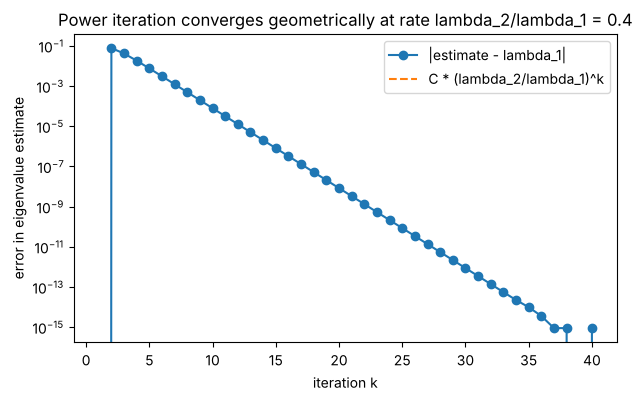

In [3]:
def power_iteration(A, n_iter=60, x0=None):
    x = np.ones(A.shape[0]) if x0 is None else np.asarray(x0, float)
    x = x / np.linalg.norm(x)
    estimates = []
    for _ in range(n_iter):
        y = A @ x
        x = y / np.linalg.norm(y)
        estimates.append(x @ A @ x)          # Rayleigh quotient
    return estimates[-1], x, np.array(estimates)

lam_est, v_est, hist = power_iteration(A, n_iter=40, x0=[1., 0.])
print("power iteration:  lambda_1 ~ %.10f,  v_1 ~ %s" % (lam_est, v_est))
print("np.linalg.eig:    lambda_1 = %.10f,  v_1 = %s" % (w[0], V[:, 0]))

err = np.abs(hist - w[0])
k = np.arange(1, len(hist) + 1)
plt.semilogy(k, err, "o-", label="|estimate - lambda_1|")
plt.semilogy(k, err[0] * (w[1] / w[0]) ** (k - 1), "--", label="C * (lambda_2/lambda_1)^k")
plt.title("Power iteration converges geometrically at rate lambda_2/lambda_1 = 0.4")
plt.xlabel("iteration k"); plt.ylabel("error in eigenvalue estimate"); plt.legend(); plt.show()

The error falls by a factor of $0.4 = \lambda_2/\lambda_1$ per step until it hits
floating-point precision near $10^{-16}$. If the two largest eigenvalues were close
(ratio 0.99) the same picture would need hundreds of iterations — the *gap* controls the speed.

### A two-state Markov chain

A column-stochastic matrix $T$ (columns sum to one) has eigenvalue $1$, and its eigenvector —
scaled to sum to one — is the stationary distribution $\pi$. Repeatedly applying $T$ *is*
power iteration, and the second eigenvalue sets how fast the chain forgets its start.

In [4]:
T = np.array([[0.9, 0.5],     # column j = where brand j's customers go next month
              [0.1, 0.5]])
w_T, P = np.linalg.eig(T)
print("eigenvalues of T:", w_T.real)
pi = P[:, np.argmax(w_T.real)].real
pi = pi / pi.sum()
print("stationary distribution pi =", pi, "  (5/6, 1/6)")

x = np.array([0., 1.])                      # everyone starts with brand B
print("\nmonth   share A   share B   distance to pi")
for month in range(1, 11):
    x = T @ x
    print(f"{month:5d}   {x[0]:7.4f}   {x[1]:7.4f}   {np.abs(x - pi).sum():.2e}")

# A^k via the diagonalisation: P D^k P^-1  equals the direct matrix power
D = np.diag(w_T.real)
Tk_diag = P.real @ np.diag(w_T.real ** 10) @ np.linalg.inv(P.real)
print("\nmax |P D^10 P^-1 - T^10| =", np.abs(Tk_diag - np.linalg.matrix_power(T, 10)).max())
print("0.4^10 =", 0.4 ** 10, " -> the second eigenvalue is the speed of forgetting")

eigenvalues of T: [1.  0.4]
stationary distribution pi = [0.8333 0.1667]   (5/6, 1/6)

month   share A   share B   distance to pi
    1    0.5000    0.5000   6.67e-01
    2    0.7000    0.3000   2.67e-01
    3    0.7800    0.2200   1.07e-01
    4    0.8120    0.1880   4.27e-02
    5    0.8248    0.1752   1.71e-02
    6    0.8299    0.1701   6.83e-03
    7    0.8320    0.1680   2.73e-03
    8    0.8328    0.1672   1.09e-03
    9    0.8331    0.1669   4.37e-04
   10    0.8332    0.1668   1.75e-04

max |P D^10 P^-1 - T^10| = 2.220446049250313e-16
0.4^10 = 0.00010485760000000006  -> the second eigenvalue is the speed of forgetting


Both brands end at the shares $(5/6, 1/6)$ whatever the starting split, and the distance to
$\pi$ shrinks by exactly $0.4$ per month — the second eigenvalue.

### PageRank on a six-page web

PageRank is the stationary distribution of a random surfer who follows a random out-link
with probability $d = 0.85$ and jumps to a uniformly random page otherwise. With $M$ the
column-stochastic link matrix (a page with no out-links is treated as linking to every page),

$$G = d\,M + \frac{1-d}{n}\,\mathbf{1}\mathbf{1}^\top, \qquad \pi = G\pi .$$

Every entry of $G$ is positive, so the stationary vector is unique and $|\lambda_2| \le d$:
power iteration converges at least as fast as $0.85^k$, however large the web.

columns of G sum to one: True
converged in 53 iterations (0.85^53 = 1.8e-04)
PageRank: [0.3487 0.1795 0.3511 0.0446 0.0313 0.0446]  sum = 1.000000000000002
ranking (best first): [2 0 1 3 5 4]
max |power iteration - eig| = 1.5798473640415978e-13
second-largest |eigenvalue| of G = 0.601  (<= d = 0.85)


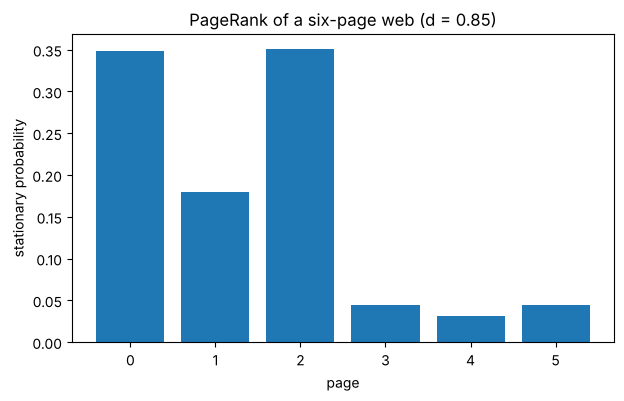

In [5]:
links = {0: [1, 2], 1: [2], 2: [0], 3: [0, 2], 4: [3, 5], 5: []}   # page 5 is a dead end
n = len(links)

M = np.zeros((n, n))                       # M[i, j] = prob. of going j -> i
for j, outs in links.items():
    if outs:
        M[outs, j] = 1.0 / len(outs)
    else:
        M[:, j] = 1.0 / n                  # dangling page: jump anywhere
d = 0.85
G = d * M + (1 - d) / n * np.ones((n, n))
print("columns of G sum to one:", np.allclose(G.sum(axis=0), 1))

x = np.ones(n) / n
for k in range(1, 200):
    x_new = G @ x
    if np.abs(x_new - x).sum() < 1e-12:
        break
    x = x_new
pagerank = x_new
print(f"converged in {k} iterations (0.85^{k} = {0.85**k:.1e})")
print("PageRank:", pagerank, " sum =", pagerank.sum())
print("ranking (best first):", np.argsort(-pagerank))

# cross-check with the eigenvector for eigenvalue 1
w_G, V_G = np.linalg.eig(G)
v1 = V_G[:, np.argmin(np.abs(w_G - 1))].real
print("max |power iteration - eig| =", np.abs(pagerank - v1 / v1.sum()).max())
print("second-largest |eigenvalue| of G = %.3f  (<= d = %.2f)" % (np.sort(np.abs(w_G))[-2], d))

plt.bar(range(n), pagerank, color="tab:blue")
plt.title("PageRank of a six-page web (d = 0.85)")
plt.xlabel("page"); plt.ylabel("stationary probability"); plt.show()

Pages 2 and 0 share the top with about 35 % each. Page 2 is linked to by three pages (0, 1
and 3); page 0 is linked to by *one* page only — but that page is page 2, the most important
one, and it sends page 0 its entire out-link weight. That is the whole idea of PageRank: a
link is worth what its source is worth. Pages 3, 4 and 5 are linked to from nobody or only
from the weak page 4, so they live mostly on the teleportation term $(1-d)/n$.

**Try it yourself:** set `d = 0.5` and then `d = 0.99`. Convergence speeds up or slows down
with $d$, and as $d \to 1$ the loop 0→1→2→0 soaks up almost all of the probability mass while
the dead-end page 5 and its only referrer, page 4, drop towards zero.

## 3. Symmetric matrices and the spectral theorem

For a symmetric matrix ($A = A^\top$) the eigenvalues are real and the eigenvectors can be
chosen orthonormal:

$$A = Q\Lambda Q^\top = \sum_i \lambda_i q_i q_i^\top, \qquad Q^\top Q = I .$$

In the eigen-coordinates $y = Q^\top x$ the quadratic form becomes a weighted sum of squares,
$x^\top A x = \sum_i \lambda_i y_i^2$, so $A$ is positive semidefinite exactly when every
$\lambda_i \ge 0$. The level set $x^\top A x = 1$ is an ellipse whose axes are the
eigenvectors and whose semi-axis lengths are $1/\sqrt{\lambda_i}$.

eigenvalues: [3. 1.]
Q (orthonormal eigenvectors as columns):
[[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
Q^T Q = I ? True
sum_i lambda_i q_i q_i^T reconstructs S ? True


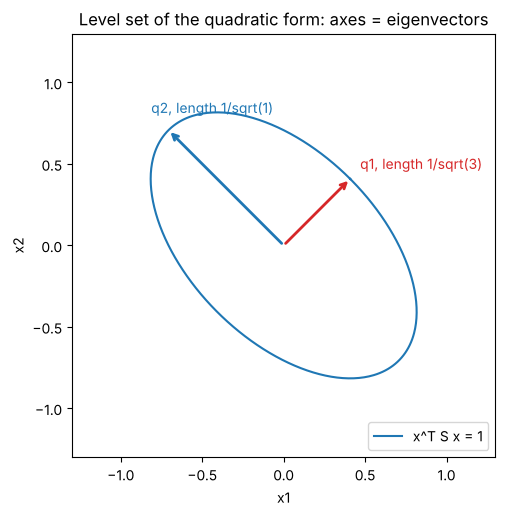

In [6]:
S = np.array([[2., 1.],
              [1., 2.]])
lam, Q = np.linalg.eigh(S)                  # eigh: symmetric input -> real, ascending
lam, Q = lam[::-1], Q[:, ::-1]              # descending
print("eigenvalues:", lam)
print("Q (orthonormal eigenvectors as columns):"); print(Q)
print("Q^T Q = I ?", np.allclose(Q.T @ Q, np.eye(2)))
recon = sum(lam[i] * np.outer(Q[:, i], Q[:, i]) for i in range(2))
print("sum_i lambda_i q_i q_i^T reconstructs S ?", np.allclose(recon, S))

# the ellipse x^T S x = 1 drawn via eigen-coordinates
theta = np.linspace(0, 2 * np.pi, 400)
y = np.vstack([np.cos(theta) / np.sqrt(lam[0]), np.sin(theta) / np.sqrt(lam[1])])
x = Q @ y
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(x[0], x[1], label="x^T S x = 1")
for i, c in enumerate(["tab:red", "tab:blue"]):
    a = Q[:, i] / np.sqrt(lam[i])
    ax.annotate("", xy=a, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    ax.text(a[0] * 1.15, a[1] * 1.15, f"q{i+1}, length 1/sqrt({lam[i]:.0f})", color=c)
ax.set_aspect("equal"); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
ax.set_title("Level set of the quadratic form: axes = eigenvectors")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(loc="lower right"); plt.show()

The ellipse is short along $q_1 = (1,1)/\sqrt2$ (semi-axis $1/\sqrt3 \approx 0.58$): the form
grows fastest there, because $\lambda_1 = 3$ is the larger eigenvalue. Now the same facts
on a larger random symmetric matrix, and the two things we most often need in ML: a
covariance matrix is PSD, and the Rayleigh quotient is squeezed between $\lambda_{\min}$ and
$\lambda_{\max}$.

In [7]:
B = rng.normal(size=(5, 5))
S5 = B @ B.T                                # Gram matrices are symmetric PSD
lam5, Q5 = np.linalg.eigh(S5)
print("eigenvalues of B B^T:", lam5, "-> all >= 0, so PSD")
print("max |Q^T Q - I| = %.1e,   max |Q L Q^T - S| = %.1e"
      % (np.abs(Q5.T @ Q5 - np.eye(5)).max(), np.abs(Q5 @ np.diag(lam5) @ Q5.T - S5).max()))

# a covariance matrix of real-looking data is PSD too
data = rng.normal(size=(200, 4)) @ rng.normal(size=(4, 4))
C = np.cov(data, rowvar=False)
print("eigenvalues of a covariance matrix:", np.linalg.eigvalsh(C))

# Rayleigh quotient of 10,000 random directions never leaves [lambda_min, lambda_max]
X = rng.normal(size=(10000, 5))
rq = np.einsum("ij,jk,ik->i", X, S5, X) / np.einsum("ij,ij->i", X, X)
print("Rayleigh quotients: min %.4f, max %.4f;  eigenvalues: min %.4f, max %.4f"
      % (rq.min(), rq.max(), lam5.min(), lam5.max()))

eigenvalues of B B^T: [0.1755 0.5349 3.5257 4.5103 7.8622] -> all >= 0, so PSD
max |Q^T Q - I| = 3.1e-16,   max |Q L Q^T - S| = 2.2e-15
eigenvalues of a covariance matrix: [ 0.4016  0.9367  4.2698 16.5128]
Rayleigh quotients: min 0.2403, max 7.7341;  eigenvalues: min 0.1755, max 7.8622


The random Rayleigh quotients stay strictly inside $[\lambda_{\min}, \lambda_{\max}]$ and
never quite reach the ends — the extremes are attained only *at* the eigenvectors. That
"maximise $w^\top C w$ over unit $w$" problem is exactly what PCA solves in Section 6.

## 4. The singular value decomposition

Any $m\times n$ matrix factors as

$$A = U\Sigma V^\top = \sum_{i=1}^{r} \sigma_i u_i v_i^\top, \qquad A v_i = \sigma_i u_i ,$$

with orthonormal $u_i$ (left singular vectors), orthonormal $v_i$ (right singular vectors)
and $\sigma_1 \ge \sigma_2 \ge \dots > 0$. The $v_i$ are eigenvectors of $A^\top A$, the $u_i$
eigenvectors of $AA^\top$, and $\sigma_i^2$ are their shared eigenvalues. Geometrically:
rotate ($V^\top$), stretch along the axes ($\Sigma$), rotate ($U$) — so the unit circle
always becomes an ellipse with semi-axes $\sigma_i u_i$.

singular values: [6.7082 2.2361]    by hand: sqrt(45), sqrt(5) = 6.708203932499369 2.23606797749979
sqrt of eigenvalues of A^T A: [6.7082 2.2361]
eigenvalues of A itself:    [5. 3.] (different!)
sigma_1 * sigma_2 = 15.0000 = |det A| = 15.0000
U^T U = I: True   V^T V = I: True
U S V^T reconstructs A: True
A v1 = [-2.1213 -6.364 ]   sigma1 u1 = [-2.1213 -6.364 ]
A v2 = [-2.1213  0.7071]   sigma2 u2 = [-2.1213  0.7071]


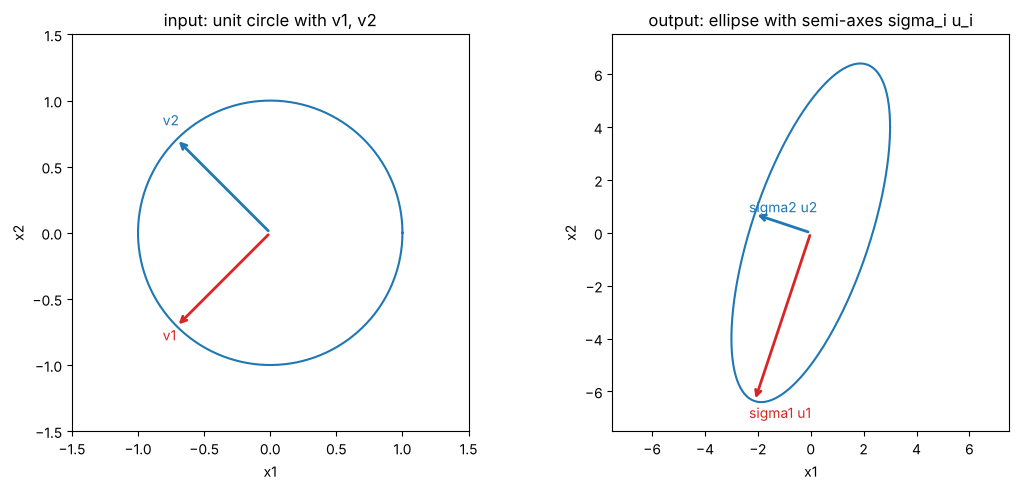

In [8]:
A2 = np.array([[3., 0.],
               [4., 5.]])
U, s, Vt = np.linalg.svd(A2)
print("singular values:", s, "   by hand: sqrt(45), sqrt(5) =", np.sqrt(45), np.sqrt(5))
print("sqrt of eigenvalues of A^T A:", np.sqrt(np.linalg.eigvalsh(A2.T @ A2)[::-1]))
print("eigenvalues of A itself:   ", np.sort(np.linalg.eigvals(A2).real)[::-1], "(different!)")
print("sigma_1 * sigma_2 = %.4f = |det A| = %.4f" % (s.prod(), abs(np.linalg.det(A2))))
print("U^T U = I:", np.allclose(U.T @ U, np.eye(2)), "  V^T V = I:", np.allclose(Vt @ Vt.T, np.eye(2)))
print("U S V^T reconstructs A:", np.allclose(U @ np.diag(s) @ Vt, A2))
for i in range(2):
    print(f"A v{i+1} = {A2 @ Vt[i]}   sigma{i+1} u{i+1} = {s[i] * U[:, i]}")

theta = np.linspace(0, 2 * np.pi, 400)
circle = np.vstack([np.cos(theta), np.sin(theta)])
image = A2 @ circle
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].plot(circle[0], circle[1]); axes[0].set_title("input: unit circle with v1, v2")
axes[1].plot(image[0], image[1]); axes[1].set_title("output: ellipse with semi-axes sigma_i u_i")
for i, c in enumerate(["tab:red", "tab:blue"]):
    axes[0].annotate("", xy=Vt[i], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    axes[0].text(Vt[i][0] * 1.15, Vt[i][1] * 1.15, f"v{i+1}", color=c)
    axes[1].annotate("", xy=s[i] * U[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    axes[1].text(s[i] * U[0, i] * 1.1, s[i] * U[1, i] * 1.1, f"sigma{i+1} u{i+1}", color=c)
for ax, lim in zip(axes, (1.5, 7.5)):
    ax.set_aspect("equal"); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.show()

The circle's diameters along $v_1$ and $v_2$ map to the ellipse's axes: $v_1$ goes to
$\sigma_1 u_1$ (length 6.71) and $v_2$ to $\sigma_2 u_2$ (length 2.24). The eigenvalues of
this matrix, 5 and 3, are *not* its singular values — only the product agrees. Signs of the
singular vectors are arbitrary (NumPy may flip a pair), which never changes the picture.

### Singular values reveal rank — even under noise

A matrix built from three rank-one pieces has exactly three non-zero singular values. Add
noise and the zeros become small-but-non-zero: the *scree plot* shows a cliff after the true
rank, which is how one decides how many components to keep.

rank of L: 3    rank of L + noise: 40
first 6 singular values, clean: [55.6478 37.7355 34.4255  0.      0.      0.    ]
first 6 singular values, noisy: [55.8946 37.8997 34.7364  3.9336  3.5492  3.4495]


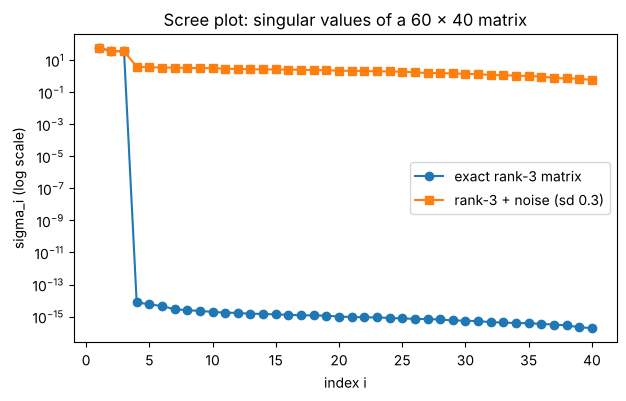

In [9]:
m, n_cols, r_true = 60, 40, 3
L = rng.normal(size=(m, r_true)) @ rng.normal(size=(r_true, n_cols))   # exact rank 3
noise = 0.3 * rng.normal(size=(m, n_cols))
s_clean = np.linalg.svd(L, compute_uv=False)
s_noisy = np.linalg.svd(L + noise, compute_uv=False)
print("rank of L:", np.linalg.matrix_rank(L), "   rank of L + noise:", np.linalg.matrix_rank(L + noise))
print("first 6 singular values, clean:", s_clean[:6])
print("first 6 singular values, noisy:", s_noisy[:6])

plt.semilogy(np.arange(1, 41), s_clean + 1e-16, "o-", label="exact rank-3 matrix")
plt.semilogy(np.arange(1, 41), s_noisy, "s-", label="rank-3 + noise (sd 0.3)")
plt.title("Scree plot: singular values of a 60 x 40 matrix")
plt.xlabel("index i"); plt.ylabel("sigma_i (log scale)"); plt.legend(); plt.show()

The clean matrix has three large singular values and the rest are at the level of rounding
error ($10^{-14}$ — `matrix_rank` correctly says 3). With noise, every singular value is
non-zero (`matrix_rank` now says 40), but the plot still shows a cliff: $\sigma_3 \approx 35$
against $\sigma_4 \approx 4$. The largest singular value of a pure-noise matrix with entries
of standard deviation $\tau$ is roughly $\tau(\sqrt{m} + \sqrt{n})$ — here
$0.3\,(\sqrt{60} + \sqrt{40}) \approx 4.2$ — a useful rule of thumb for deciding whether a
singular value is "signal".

**Try it yourself:** raise the noise standard deviation to `1.5`. At what level does the
cliff disappear, so that the true rank is no longer readable from the plot?

## 5. Low-rank approximation — image compression

Keeping the $k$ largest terms of the SVD gives $A_k = \sum_{i \le k} \sigma_i u_i v_i^\top$,
and the **Eckart–Young theorem** says no rank-$k$ matrix is closer:

$$\|A - A_k\|_F = \sqrt{\textstyle\sum_{i>k}\sigma_i^2}, \qquad \|A - A_k\|_2 = \sigma_{k+1} .$$

Storing $A_k$ costs $k(m + n + 1)$ numbers instead of $mn$. We compress a synthetic $64\times64$
image and check the theorem's error formula against the directly measured error.

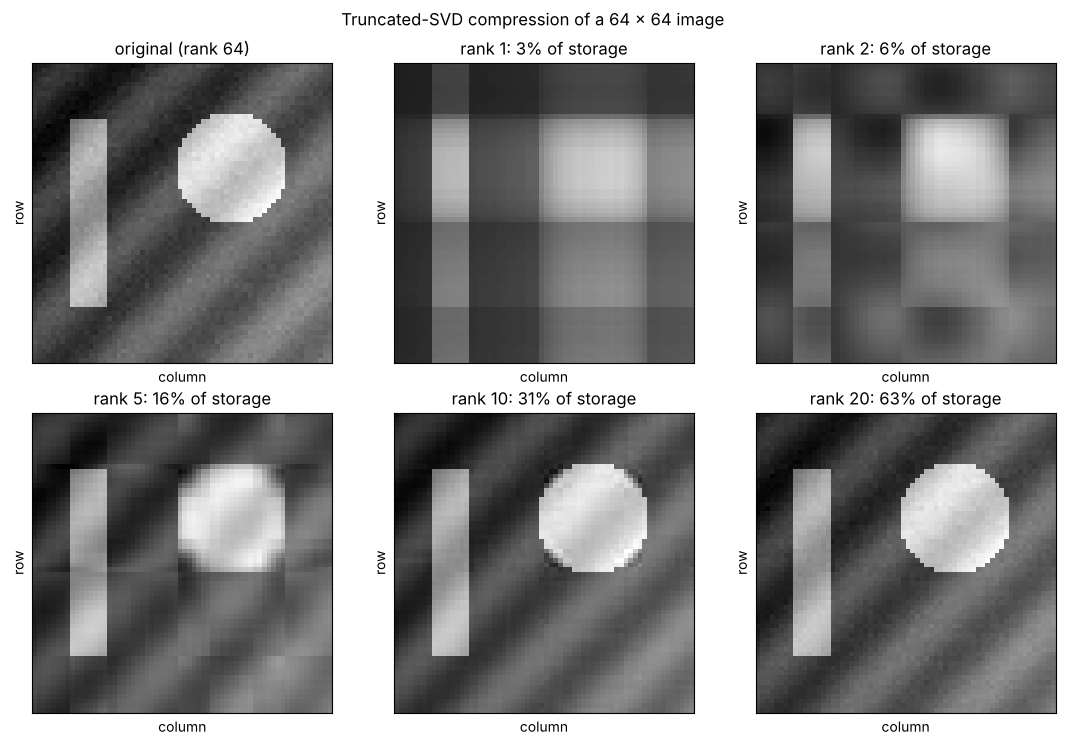

In [10]:
yy, xx = np.mgrid[0:64, 0:64]
img = 0.3 * xx / 63 + 0.2 * yy / 63                       # smooth gradient (rank 2)
img = img + 0.6 * (((xx - 42) ** 2 + (yy - 22) ** 2) < 12 ** 2)   # a disc
img[12:52, 8:16] += 0.5                                    # a vertical bar
img = img + 0.12 * np.sin((xx + yy) / 4.0)                 # diagonal stripes (rank 2)
img = img + 0.02 * rng.normal(size=img.shape)              # a little sensor noise

U, s, Vt = np.linalg.svd(img)
def rank_k(U, s, Vt, k):
    return (U[:, :k] * s[:k]) @ Vt[:k]

ks = [1, 2, 5, 10, 20]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
axes = axes.ravel()
axes[0].imshow(img, cmap="gray"); axes[0].set_title("original (rank %d)" % np.linalg.matrix_rank(img))
for ax, k in zip(axes[1:], ks):
    ax.imshow(rank_k(U, s, Vt, k), cmap="gray", vmin=img.min(), vmax=img.max())
    ax.set_title(f"rank {k}: {k * (64 + 64 + 1) / 64**2:.0%} of storage")
for ax in axes:
    ax.set_xlabel("column"); ax.set_ylabel("row"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Truncated-SVD compression of a 64 x 64 image"); plt.tight_layout(); plt.show()

max |measured - Eckart-Young formula| = 1.0041122772637917e-13
k =  1: relative Frobenius error 0.363,  energy captured 86.8%
k =  2: relative Frobenius error 0.289,  energy captured 91.6%
k =  5: relative Frobenius error 0.117,  energy captured 98.6%
k = 10: relative Frobenius error 0.051,  energy captured 99.7%
k = 20: relative Frobenius error 0.028,  energy captured 99.9%


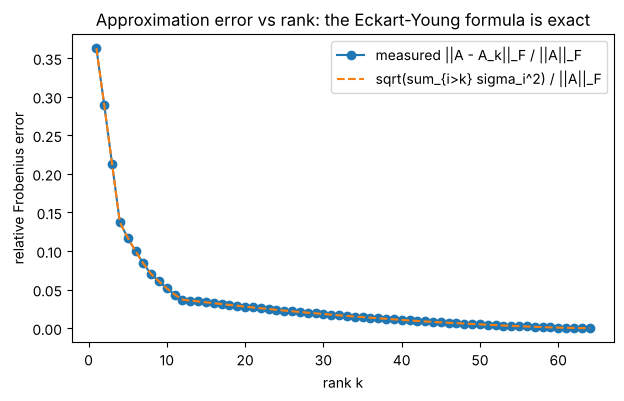

In [11]:
total_energy = (s ** 2).sum()
ks_all = np.arange(1, 65)
measured = np.array([np.linalg.norm(img - rank_k(U, s, Vt, k)) for k in ks_all])
eckart_young = np.sqrt(np.cumsum(s[::-1] ** 2)[::-1][1:].tolist() + [0.0])   # sqrt(sum_{i>k} sigma_i^2)
print("max |measured - Eckart-Young formula| =", np.abs(measured - eckart_young).max())
for k in ks:
    print(f"k = {k:2d}: relative Frobenius error {measured[k-1] / np.linalg.norm(img):.3f},"
          f"  energy captured {(s[:k]**2).sum() / total_energy:.1%}")

plt.plot(ks_all, measured / np.linalg.norm(img), "o-", label="measured ||A - A_k||_F / ||A||_F")
plt.plot(ks_all, eckart_young / np.linalg.norm(img), "--", label="sqrt(sum_{i>k} sigma_i^2) / ||A||_F")
plt.title("Approximation error vs rank: the Eckart-Young formula is exact")
plt.xlabel("rank k"); plt.ylabel("relative Frobenius error"); plt.legend(); plt.show()

Rank 1 is a blur of row and column averages; rank 5 shows every shape; rank 10 is visually
indistinguishable from the original at 31 % of the storage. The measured error curve sits
exactly on the Eckart–Young formula — the theorem is not an approximation. The clean image
has rank 12 (a gradient of rank 2, stripes of rank 2, a disc and a bar), so the singular
values beyond the twelfth are pure sensor noise; the error curve bends at $k \approx 12$ and
then declines slowly, and truncating there actually *denoises* the picture.

## 6. PCA from scratch — and against scikit-learn

For a centred data matrix $X_c$ ($n$ rows, $d$ features), the principal components are the
eigenvectors of the covariance $C = X_c^\top X_c/(n-1)$, or equivalently the right singular
vectors of $X_c$ with $\lambda_i = \sigma_i^2/(n-1)$. The explained variance ratio is
$\lambda_i / \sum_j \lambda_j$; scores are $Z = X_c V_k$; the reconstruction is
$\hat X = Z V_k^\top + \mu$.

We do all of it on the Iris data (150 flowers, 4 measurements in cm) both ways, then call
`sklearn.decomposition.PCA` and confirm it agrees to machine precision.

explained variance ratio, covariance route: [0.9246 0.0531 0.0171 0.0052]
explained variance ratio, SVD route:        [0.9246 0.0531 0.0171 0.0052]
explained variance ratio, sklearn:          [0.9246 0.0531 0.0171 0.0052]
components agree up to sign (cov vs sklearn): True
components agree up to sign (SVD vs sklearn): True
first component (loadings on sepal len, sepal wid, petal len, petal wid): [ 0.3614 -0.0845  0.8567  0.3583]

k = 2: variance explained 97.77%
total squared reconstruction error 15.2046  =  (n-1) * sum of dropped eigenvalues 15.2046


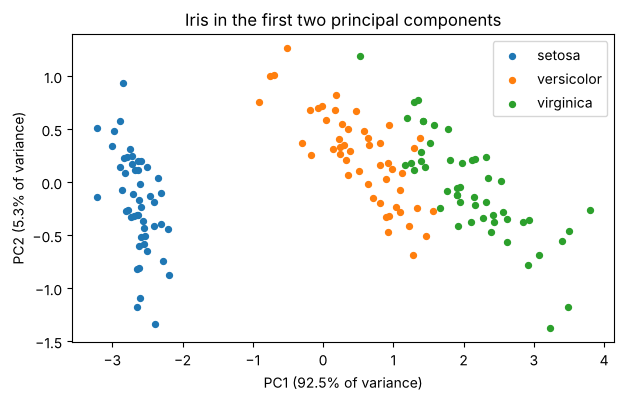

In [12]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X, y_lab = iris.data, iris.target
n_samples, d = X.shape
mu = X.mean(axis=0)
Xc = X - mu

# route 1: eigenvectors of the covariance matrix
C = Xc.T @ Xc / (n_samples - 1)
lam, W = np.linalg.eigh(C)
lam, W = lam[::-1], W[:, ::-1]
evr_cov = lam / lam.sum()

# route 2: SVD of the centred data (never forms C)
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
lam_svd = s ** 2 / (n_samples - 1)
evr_svd = lam_svd / lam_svd.sum()

# route 3: scikit-learn
pca = PCA().fit(X)

print("explained variance ratio, covariance route:", evr_cov)
print("explained variance ratio, SVD route:       ", evr_svd)
print("explained variance ratio, sklearn:         ", pca.explained_variance_ratio_)
print("components agree up to sign (cov vs sklearn):", np.allclose(np.abs(W.T), np.abs(pca.components_)))
print("components agree up to sign (SVD vs sklearn):", np.allclose(np.abs(Vt), np.abs(pca.components_)))
print("first component (loadings on sepal len, sepal wid, petal len, petal wid):", Vt[0])

k = 2
Z = Xc @ Vt[:k].T                         # scores = new coordinates
X_hat = Z @ Vt[:k] + mu                   # rank-2 reconstruction
resid = ((X - X_hat) ** 2).sum()
print(f"\nk = {k}: variance explained {evr_svd[:k].sum():.2%}")
print("total squared reconstruction error %.4f  =  (n-1) * sum of dropped eigenvalues %.4f"
      % (resid, (n_samples - 1) * lam_svd[k:].sum()))

for cls, name in enumerate(iris.target_names):
    plt.scatter(Z[y_lab == cls, 0], Z[y_lab == cls, 1], s=18, label=name)
plt.title("Iris in the first two principal components")
plt.xlabel(f"PC1 ({evr_svd[0]:.1%} of variance)"); plt.ylabel(f"PC2 ({evr_svd[1]:.1%} of variance)")
plt.legend(); plt.show()

All three routes give the same numbers: PC1 carries 92.5 % of the variance and PC2 another
5.3 %, so the 2-D picture keeps 97.8 % of the spread of the 4-D cloud. The loadings of PC1
are all the same sign and largest on petal length: the first component is essentially
"overall flower size". The three species separate well on PC1 — but remember PCA never saw
the labels; it found the direction of largest *variance*, which here happens to coincide with
species.

### What happens without scaling

PCA is not scale-invariant. Suppose one lab recorded petal length in micrometres
(a factor 10,000 larger) rather than centimetres.

In [13]:
X_bad = X.copy()
X_bad[:, 2] *= 10_000                       # petal length now in micrometres
evr_bad = PCA().fit(X_bad).explained_variance_ratio_
comp_bad = PCA().fit(X_bad).components_[0]
print("explained variance ratio with one feature in micrometres:", evr_bad)
print("first component:", comp_bad, "-> it is just the petal-length axis")

X_std = (X_bad - X_bad.mean(axis=0)) / X_bad.std(axis=0, ddof=1)   # standardise every column
evr_std = PCA().fit(X_std).explained_variance_ratio_
print("\nafter standardising each column:", evr_std)
print("first component:", PCA().fit(X_std).components_[0])
print("(the same as standardising the original cm data:", np.allclose(
      evr_std, PCA().fit((X - mu) / X.std(axis=0, ddof=1)).explained_variance_ratio_), ")")

explained variance ratio with one feature in micrometres: [1. 0. 0. 0.]
first component: [ 0. -0.  1.  0.] -> it is just the petal-length axis

after standardising each column: [0.7296 0.2285 0.0367 0.0052]
first component: [ 0.5211 -0.2693  0.5804  0.5649]
(the same as standardising the original cm data: True )


With one badly scaled feature, "PC1 explains 99.99999 % of the variance" — and it is just
that feature. Standardising restores a sensible split (73 %, 23 %, ...) that does not depend
on the units anyone chose. When features have different units, standardise first.

**Try it yourself:** compute the cumulative explained variance `np.cumsum(evr_std)` and find
the smallest $k$ that captures 99 %. Then repeat for `load_wine()` (13 features) — how many
components does it need?

## 7. The pseudo-inverse and least squares via the SVD

$$A^{+} = V\Sigma^{+}U^\top, \qquad \Sigma^{+}_{ii} = 1/\sigma_i \ \text{ if } \sigma_i > 0,\ \text{ else } 0,
\qquad x^{+} = A^{+}b = \sum_{\sigma_i>0}\frac{u_i^\top b}{\sigma_i}\,v_i .$$

$x^{+}$ minimises $\|Ax - b\|$ and, among all minimisers, has the smallest norm. It exists
even when $A^\top A$ is singular — the case the normal equations cannot handle. We build it
for a calibration problem with two perfectly collinear sensors (the same temperature in
Celsius and Fahrenheit).

In [14]:
def pinv_svd(A, rcond=1e-12):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    s_plus = np.where(s > rcond * s.max(), 1.0 / np.where(s > 0, s, 1.0), 0.0)
    return Vt.T @ (s_plus[:, None] * U.T)

celsius = np.array([20., 25., 30., 35., 40., 45.])
fahrenheit = 1.8 * celsius + 32                       # exactly collinear with [1, celsius]
hardness = 50 + 0.8 * celsius + rng.normal(0, 0.5, size=6)
Xd = np.column_stack([np.ones(6), celsius, fahrenheit])  # design matrix, rank 2

print("singular values of the design matrix:", np.linalg.svd(Xd, compute_uv=False))
print("rank:", np.linalg.matrix_rank(Xd), " -> X^T X is singular, cond =", np.linalg.cond(Xd.T @ Xd))

coef_min = pinv_svd(Xd) @ hardness
print("\nour pinv agrees with np.linalg.pinv:", np.allclose(pinv_svd(Xd), np.linalg.pinv(Xd)))
print("lstsq gives the same coefficients:", np.allclose(coef_min, np.linalg.lstsq(Xd, hardness, rcond=None)[0]))
print("minimum-norm coefficients [intercept, C, F]:", coef_min, " norm = %.4f" % np.linalg.norm(coef_min))

# any null-space direction gives the SAME fit but a LONGER coefficient vector
null_dir = np.array([32., 1.8, -1.])      # 32*1 + 1.8*C - F = 0 for every row
print("X @ null_dir = 0 ?", np.allclose(Xd @ null_dir, 0))
coef_other = coef_min + 0.5 * null_dir
print("same predictions ?", np.allclose(Xd @ coef_other, Xd @ coef_min),
      "  norm = %.4f (larger)" % np.linalg.norm(coef_other))
print("residual of the fit: %.4f" % np.linalg.norm(Xd @ coef_min - hardness))

singular values of the design matrix: [239.3593   6.8638   0.    ]
rank: 2  -> X^T X is singular, cond = 1.440404004985086e+17

our pinv agrees with np.linalg.pinv: True
lstsq gives the same coefficients: True
minimum-norm coefficients [intercept, C, F]: [ 0.1589 -1.9673  1.5445]  norm = 2.5062
X @ null_dir = 0 ? True
same predictions ? True   norm = 16.2278 (larger)
residual of the fit: 1.8205


The third singular value is zero (up to rounding), so $X^\top X$ cannot be inverted — but
`pinv_svd` simply skips that direction and returns the shortest coefficient vector that fits
the data. Adding any multiple of the null-space direction $(32, 1.8, -1)$ leaves every
prediction unchanged and only makes the coefficients longer. That is why `np.linalg.lstsq`
and `sklearn.linear_model.LinearRegression` are SVD-based.

**Ridge regression** softens the hard cut-off: instead of $1/\sigma_i$ (or $0$) it uses the
filter $\sigma_i/(\sigma_i^2 + \lambda)$, which leaves large singular values alone and
shrinks small ones towards zero.

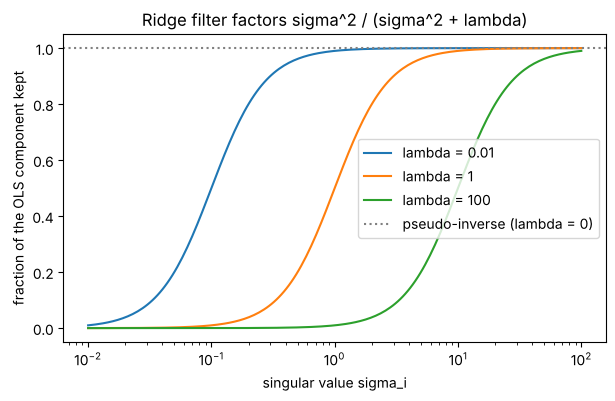

A direction with sigma = 0.1 and lambda = 1 keeps only 1.0% of its OLS coefficient.


In [15]:
sig = np.logspace(-2, 2, 200)
for lam_ridge in [0.01, 1.0, 100.0]:
    plt.semilogx(sig, sig ** 2 / (sig ** 2 + lam_ridge), label=f"lambda = {lam_ridge:g}")
plt.axhline(1.0, color="gray", ls=":", label="pseudo-inverse (lambda = 0)")
plt.title("Ridge filter factors sigma^2 / (sigma^2 + lambda)")
plt.xlabel("singular value sigma_i"); plt.ylabel("fraction of the OLS component kept"); plt.legend(); plt.show()
print("A direction with sigma = 0.1 and lambda = 1 keeps only %.1f%% of its OLS coefficient."
      % (100 * 0.1 ** 2 / (0.1 ** 2 + 1)))

Directions with $\sigma_i^2 \gg \lambda$ pass unchanged; directions with $\sigma_i^2 \ll
\lambda$ — the ones the data barely constrain and that amplify noise most — are nearly
removed. Module 13 derives this and shows why it reduces variance.

## 8. Condition number and numerical stability

$$\kappa(A) = \frac{\sigma_{\max}}{\sigma_{\min}}, \qquad
\frac{\|\delta x\|}{\|x\|} \le \kappa(A)\,\frac{\|\delta b\|}{\|b\|}.$$

We manufacture matrices with a prescribed $\kappa$ (random orthogonal $U$, $V$ and chosen
singular values), perturb $b$ by one part in $10^8$, and measure how much the solution of
$Ax = b$ moves — for random perturbations and for the worst-case direction.

kappa =     1e+00:  np.linalg.cond =  1.00e+00,  amplification random  1.00e+00,  worst case  1.00e+00
kappa =     1e+01:  np.linalg.cond =  1.00e+01,  amplification random  2.84e+00,  worst case  1.00e+01
kappa =     1e+02:  np.linalg.cond =  1.00e+02,  amplification random  4.48e+00,  worst case  1.00e+02
kappa =     1e+03:  np.linalg.cond =  1.00e+03,  amplification random  1.08e+02,  worst case  1.00e+03
kappa =     1e+04:  np.linalg.cond =  1.00e+04,  amplification random  1.86e+02,  worst case  1.00e+04
kappa =     1e+05:  np.linalg.cond =  1.00e+05,  amplification random  1.74e+04,  worst case  1.00e+05
kappa =     1e+06:  np.linalg.cond =  1.00e+06,  amplification random  1.89e+05,  worst case  1.00e+06
kappa =     1e+07:  np.linalg.cond =  1.00e+07,  amplification random  2.16e+05,  worst case  1.00e+07
kappa =     1e+08:  np.linalg.cond =  1.00e+08,  amplification random  7.90e+05,  worst case  1.00e+08


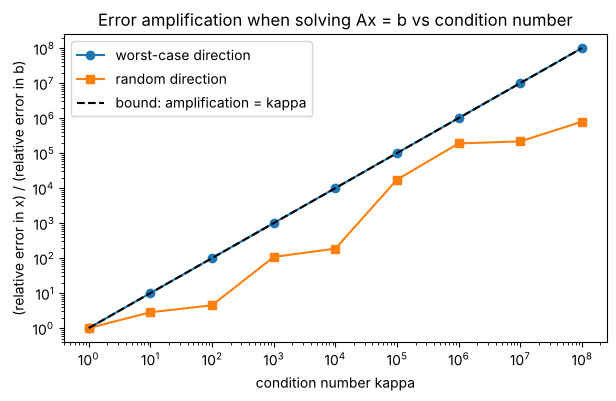

In [16]:
def random_orthogonal(n):
    Q, _ = np.linalg.qr(rng.normal(size=(n, n)))
    return Q

def matrix_with_condition(n, kappa):
    U, V = random_orthogonal(n), random_orthogonal(n)
    s = np.logspace(0, -np.log10(kappa), n)       # sigma from 1 down to 1/kappa
    return U @ np.diag(s) @ V.T, U, V, s

n = 8
kappas = np.logspace(0, 8, 9)
amp_random, amp_worst = [], []
for kappa in kappas:
    A_k, U, V, s = matrix_with_condition(n, kappa)
    # random perturbation of a random right-hand side
    x_true = rng.normal(size=n); b = A_k @ x_true
    db = rng.normal(size=n); db = 1e-8 * np.linalg.norm(b) * db / np.linalg.norm(db)
    x_pert = np.linalg.solve(A_k, b + db)
    amp_random.append((np.linalg.norm(x_pert - x_true) / np.linalg.norm(x_true)) / 1e-8)
    # worst case: b along u_1 (strong direction), db along u_n (weak direction)
    b_w = U[:, 0]; db_w = 1e-8 * U[:, -1]
    x_w = np.linalg.solve(A_k, b_w); x_wp = np.linalg.solve(A_k, b_w + db_w)
    amp_worst.append((np.linalg.norm(x_wp - x_w) / np.linalg.norm(x_w)) / 1e-8)
    print(f"kappa = {kappa:9.0e}:  np.linalg.cond = {np.linalg.cond(A_k):9.2e},"
          f"  amplification random {amp_random[-1]:9.2e},  worst case {amp_worst[-1]:9.2e}")

plt.loglog(kappas, amp_worst, "o-", label="worst-case direction")
plt.loglog(kappas, amp_random, "s-", label="random direction")
plt.loglog(kappas, kappas, "k--", label="bound: amplification = kappa")
plt.title("Error amplification when solving Ax = b vs condition number")
plt.xlabel("condition number kappa"); plt.ylabel("(relative error in x) / (relative error in b)")
plt.legend(); plt.show()

The worst-case amplification sits exactly on the line $\kappa$ — the bound is tight. Random
perturbations do less damage but still grow with $\kappa$: with $\kappa = 10^8$ a change in
the eighth decimal of $b$ moves $x$ in the first decimal. Rule of thumb: you lose
$\log_{10}\kappa$ digits.

### Why ill-conditioning slows gradient descent

On the quadratic $f(x) = \tfrac12 x^\top A x$ with eigenvalues $\lambda_{\max}$ and
$\lambda_{\min}$, gradient descent with the best fixed step $\eta = 2/(\lambda_{\max} +
\lambda_{\min})$ shrinks the error by $(\kappa - 1)/(\kappa + 1)$ per step. Let's count steps.

kappa =      1:      1 steps to shrink the error 1000x   (theory ~        1)
kappa =      2:      7 steps to shrink the error 1000x   (theory ~        6)
kappa =      5:     18 steps to shrink the error 1000x   (theory ~       17)
kappa =     10:     35 steps to shrink the error 1000x   (theory ~       34)
kappa =     30:    104 steps to shrink the error 1000x   (theory ~      104)
kappa =    100:    346 steps to shrink the error 1000x   (theory ~      345)
kappa =    300:   1037 steps to shrink the error 1000x   (theory ~     1036)
kappa =   1000:   3454 steps to shrink the error 1000x   (theory ~     3454)
kappa =   3000:  10362 steps to shrink the error 1000x   (theory ~    10362)
kappa =  10000:  34539 steps to shrink the error 1000x   (theory ~    34539)


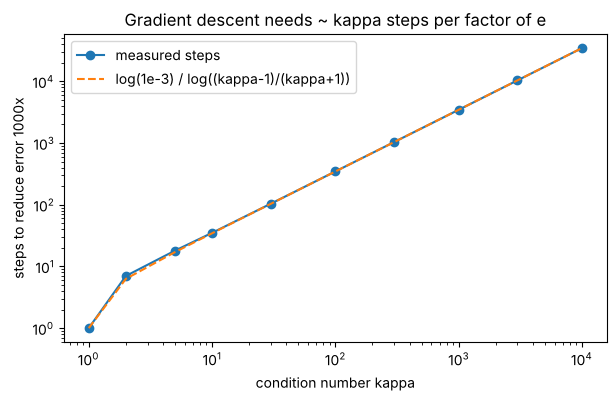

In [17]:
def gd_steps_to_tolerance(kappa, tol=1e-3, max_steps=200_000):
    A_q = np.diag([1.0, kappa])                    # eigenvalues 1 and kappa
    eta = 2.0 / (1.0 + kappa)                      # optimal fixed step size
    x = np.array([1.0, 1.0]); x0_norm = np.linalg.norm(x)
    for step in range(1, max_steps + 1):
        x = x - eta * (A_q @ x)                    # gradient of 0.5 x^T A x is A x
        if np.linalg.norm(x) < tol * x0_norm:
            return step
    return max_steps

kappas_gd = np.array([1, 2, 5, 10, 30, 100, 300, 1000, 3000, 10000])
steps = np.array([gd_steps_to_tolerance(k) for k in kappas_gd])
ratio = (kappas_gd - 1) / (kappas_gd + 1)
predicted = np.ones_like(kappas_gd, dtype=float)
predicted[kappas_gd > 1] = np.log(1e-3) / np.log(ratio[kappas_gd > 1])   # kappa = 1 converges in one step
for k_, s_, p_ in zip(kappas_gd, steps, predicted):
    print(f"kappa = {k_:6d}: {s_:6d} steps to shrink the error 1000x   (theory ~ {p_:8.0f})")

plt.loglog(kappas_gd, steps, "o-", label="measured steps")
plt.loglog(kappas_gd, predicted, "--", label="log(1e-3) / log((kappa-1)/(kappa+1))")
plt.title("Gradient descent needs ~ kappa steps per factor of e")
plt.xlabel("condition number kappa"); plt.ylabel("steps to reduce error 1000x"); plt.legend(); plt.show()

The step count grows linearly with $\kappa$: ten times worse conditioning, ten times more
iterations. Module 05 shows how momentum and Adam attack this; the cheapest fix of all is to
make $\kappa$ small in the first place by **scaling the features**.

In [18]:
# A polynomial-trend design matrix on raw calendar years vs centred years
years = np.arange(1990, 2021, dtype=float)
X_raw = np.column_stack([np.ones_like(years), years, years ** 2])
X_cen = np.column_stack([np.ones_like(years), years - 2005, (years - 2005) ** 2])
print("condition number, raw years:     %.2e" % np.linalg.cond(X_raw))
print("condition number, centred years: %.2e" % np.linalg.cond(X_cen))

# Correlated features with wildly different scales, before and after standardising
Z = rng.normal(size=(500, 3)) @ np.array([[1, 0.9, 0.0], [0, 0.4, 0.0], [0, 0, 1.0]])
Z = Z * np.array([1.0, 1000.0, 0.01])        # different units
Z_std = (Z - Z.mean(axis=0)) / Z.std(axis=0)
print("\ncondition number of X^T X, raw features:          %.2e" % np.linalg.cond(Z.T @ Z))
print("condition number of X^T X, standardised features: %.2e" % np.linalg.cond(Z_std.T @ Z_std))
print("(the remaining conditioning comes from the 0.9 correlation, which scaling cannot remove)")

condition number, raw years:     2.26e+11
condition number, centred years: 1.61e+02

condition number of X^T X, raw features:          8.55e+09
condition number of X^T X, standardised features: 2.18e+01
(the remaining conditioning comes from the 0.9 correlation, which scaling cannot remove)


Centring the year variable cuts the condition number from about $10^{11}$ to about $10^2$ —
same model, same fitted curve, nine orders of magnitude less error amplification.
Standardising the three-feature design matrix removes the damage done by units; what remains
is genuine correlation between features, which only regularisation (Section 7, Module 13)
or dropping features can address.

**Try it yourself:** in `gd_steps_to_tolerance`, use the "safe" step `eta = 1.0 / kappa`
instead of the optimal one. How does the step count change?

## Summary

- Eigenvectors are the directions a square matrix only stretches; for a $2\times2$ matrix
  the eigenvalues solve $\lambda^2 - \operatorname{tr}A\,\lambda + \det A = 0$.
- $A^k = PD^kP^{-1}$: the dominant eigenvalue takes over, which is why power iteration
  works, why Markov chains converge to the eigenvector with eigenvalue 1, and why PageRank
  with damping converges in a few dozen steps.
- Symmetric matrices have real eigenvalues and orthonormal eigenvectors ($A = Q\Lambda Q^\top$);
  positive semidefinite means all $\lambda_i \ge 0$, and the Rayleigh quotient lives in
  $[\lambda_{\min}, \lambda_{\max}]$.
- Every matrix has an SVD $A = U\Sigma V^\top$: rotate, stretch, rotate. Singular values
  reveal rank, norms and noise floors.
- Truncating the SVD at rank $k$ is the best rank-$k$ approximation (Eckart–Young), with
  error exactly $\sqrt{\sum_{i>k}\sigma_i^2}$ — the basis of compression, denoising and LoRA.
- PCA = eigenvectors of the covariance = right singular vectors of the centred data;
  scikit-learn agrees to machine precision; scale your features first.
- The pseudo-inverse $V\Sigma^+U^\top$ gives the minimum-norm least-squares solution even
  for rank-deficient problems; ridge regression is a soft version of its cut-off.
- The condition number $\sigma_{\max}/\sigma_{\min}$ bounds error amplification exactly and
  sets the number of gradient-descent steps; centring and standardising shrink it.

## Next: open `exercises.ipynb`

Twelve exercises with instant self-checks, from eigenvalues by hand to a latent-factor
recommender built from truncated SVDs.